In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from src.features import make_features


In [2]:
df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()
print(df_clean.shape, temp.shape, len(train_buildings))

(17544, 1578) (17544, 19) 1083


In [3]:
b = "Robin_lodging_Dorthy"
site = b.split("_")[0]
s = df_clean[b]

feat = pd.DataFrame({
    "load": s,
    "hour": s.index.hour,
    "weekday": s.index.weekday,
    "lag24": s.shift(24),
    "lag168": s.shift(168),
    "temp": temp[site],
})
feat.loc["2016-01-08":].head(10)

,load,hour,weekday,lag24,lag168,temp
2016-01-08 00:00:00,33.4,0,4,32.6,14.3,3.3
2016-01-08 01:00:00,28.0,1,4,25.4,27.3,3.2
2016-01-08 02:00:00,23.9,2,4,20.8,25.7,2.6
2016-01-08 03:00:00,20.4,3,4,19.2,22.4,2.7
2016-01-08 04:00:00,19.8,4,4,18.4,20.1,1.9
2016-01-08 05:00:00,19.6,5,4,18.1,18.6,2.4
2016-01-08 06:00:00,19.2,6,4,17.7,17.4,1.6
2016-01-08 07:00:00,20.1,7,4,19.5,19.5,4.2
2016-01-08 08:00:00,24.6,8,4,22.9,22.1,4.4
2016-01-08 09:00:00,32.3,9,4,30.7,26.1,5.8


In [4]:
features = ["hour", "weekday", "lag24", "lag168", "temp"]

train = feat.loc["2016"].dropna(subset=["load"])
test = feat.loc["2017"].dropna(subset=["load"])

model = HistGradientBoostingRegressor(random_state=0)
model.fit(train[features], train["load"])

pred = model.predict(test[features])
mae_model = (test["load"] - pred).abs().mean()
print("model MAE:", round(mae_model, 2), " | baselines: last week 3.42, yesterday 3.00")

model MAE: 2.56  | baselines: last week 3.42, yesterday 3.00


In [5]:
features_no_temp = ["hour", "weekday", "lag24", "lag168"]

model2 = HistGradientBoostingRegressor(random_state=0)
model2.fit(train[features_no_temp], train["load"])
pred2 = model2.predict(test[features_no_temp])
mae_no_temp = (test["load"] - pred2).abs().mean()
print("with temp:", round(mae_model, 2), " | without temp:", round(mae_no_temp, 2), " | yesterday:", 3.00)

with temp: 2.56  | without temp: 2.57  | yesterday: 3.0


In [10]:
# 4. Train and score two models: with and without temperature
def train_and_score(features):
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(train[features], train["load"])
    pred = model.predict(test[features])
    return (test["load"] - pred).abs().mean()

mae_with = train_and_score(["hour", "weekday", "lag24", "lag168", "temp"])
mae_without = train_and_score(["hour", "weekday", "lag24", "lag168"])

# 5. Baselines on the same test hours
mae_yesterday = (test["load"] - test["lag24"]).abs().mean()
mae_lastweek = (test["load"] - test["lag168"]).abs().mean()

print("model with temp:   ", round(mae_with, 2))
print("model without temp:", round(mae_without, 2))
print("baseline yesterday:", round(mae_yesterday, 2))
print("baseline last week:", round(mae_lastweek, 2))

model with temp:    14.28
model without temp: 14.32
baseline yesterday: 16.69
baseline last week: 17.67


In [11]:
# as it can be seen the temp feature do not change the result so much, it might be because of the type or location of the building after experimenting on all the building we can conclude the role of temp on the model



In [12]:
# Global model
import numpy as np

rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)

def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site]})

data = pd.concat([make_features(b) for b in sample])
features = ["hour", "weekday", "lag24", "lag168", "temp"]

train = data[data.index.year == 2016].dropna(subset=["load"])
test = data[data.index.year == 2017].dropna(subset=["load"]).copy()

model = HistGradientBoostingRegressor(random_state=0)
model.fit(train[features], train["load"])
test["pred"] = model.predict(test[features])

by_b = test.groupby("building")
mae_model = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
mae_yest = by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean())
mae_week = by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean())
best_base = np.minimum(mae_yest, mae_week)

print(len(train), "training rows")
print("model beats the stronger baseline for", (mae_model < best_base).mean().round(2), "of buildings")
print("median improvement:", ((best_base - mae_model) / best_base).median().round(3))

851136 training rows
model beats the stronger baseline for 0.58 of buildings
median improvement: 0.025


In [13]:
# for 4 out of 10 buildings, copying yesterday or last week is still better.

In [14]:
scale = train.groupby("building")["load"].mean()

for df in (train, test):
    df["scale"] = df["building"].map(scale)
    for col in ["load", "lag24", "lag168"]:
        df[col + "_n"] = df[col] / df["scale"]

features_n = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]

model_n = HistGradientBoostingRegressor(random_state=0)
model_n.fit(train[features_n], train["load_n"])
test["pred_n"] = model_n.predict(test[features_n]) * test["scale"]

mae_model_n = test.groupby("building").apply(lambda g: (g["load"] - g["pred_n"]).abs().mean())
print("normalised model beats the stronger baseline for", (mae_model_n < best_base).mean().round(2), "of buildings")
print("median improvement:", ((best_base - mae_model_n) / best_base).median().round(3))

normalised model beats the stronger baseline for 0.75 of buildings
median improvement: 0.099


In [15]:
# Per-building normalisation, with the scale computed on training data only, raised the share of buildings beating the stronger naive baseline from 58% to 75%.


In [16]:
improve = (best_base - mae_model_n) / best_base
result = pd.DataFrame({"improve": improve,
                       "type": improve.index.str.split("_").str[1],
                       "site": improve.index.str.split("_").str[0]})
print(result.groupby("type")["improve"].agg(["median", "count"]).sort_values("median"))
print(result.sort_values("improve").head(10))

              median  count
type                       
services   -0.159360      1
industrial -0.027197      2
lodging    -0.022637     11
parking    -0.019219      2
health      0.028869      1
assembly    0.049470     10
public      0.070946     19
science     0.097188      2
office      0.146388     22
education   0.164558     30
                        improve        type      site
building                                             
Rat_assembly_Pam      -6.499608    assembly       Rat
Hog_office_Gustavo    -1.068769      office       Hog
Moose_education_Maria -0.279781   education     Moose
Fox_parking_Felipa    -0.205985     parking       Fox
Cockatoo_lodging_Kyle -0.185593     lodging  Cockatoo
Bull_services_Nadine  -0.159360    services      Bull
Hog_industrial_Jay    -0.131519  industrial       Hog
Rat_public_Caroline   -0.113877      public       Rat
Rat_assembly_Aisha    -0.111525    assembly       Rat
Rat_assembly_Jamie    -0.095443    assembly       Rat


<Axes: title={'center': 'Rat_assembly_Pam'}>

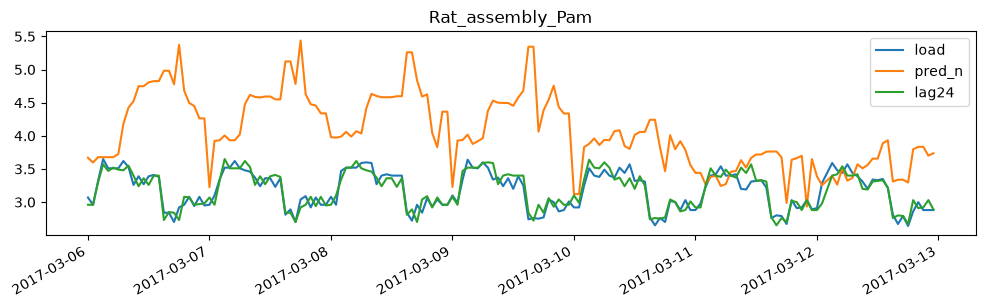

In [17]:
worst = result.sort_values("improve").index[0]
w = test[test["building"] == worst].loc["2017-03-06":"2017-03-12"]
w[["load", "pred_n", "lag24"]].plot(figsize=(12, 3), title=worst)

<Axes: title={'center': 'Rat_assembly_Pam: monthly mean'}, xlabel='timestamp'>

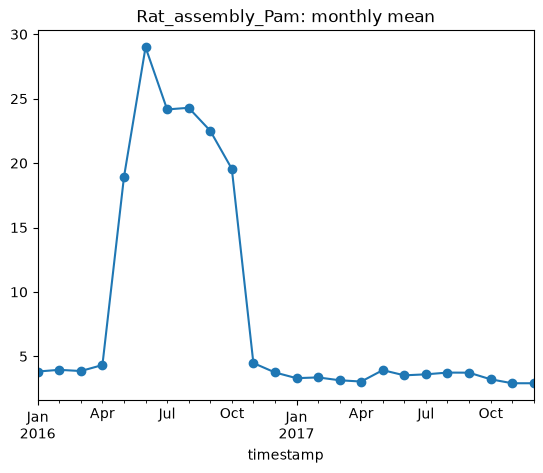

In [18]:
df_clean["Rat_assembly_Pam"].resample("MS").mean().plot(marker="o", title="Rat_assembly_Pam: monthly mean")

In [19]:
# Rat_assembly_Pam used about 4 kWh most of the time, but from May to October 2016 it jumped to about 19–29 kWh, then dropped back to about 3–4 for good. So its 2016 average is pulled far up by those 6 months, and every 2017 forecast gets scaled with a number that no longer describes the building.


In [20]:
def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    recent = recent.where(recent > 0.01)
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site], "scale": recent})

data = pd.concat([make_features(b) for b in sample])
for col in ["load", "lag24", "lag168"]:
    data[col + "_n"] = data[col] / data["scale"]

train = data[data.index.year == 2016].dropna(subset=["load_n"])
test = data[data.index.year == 2017].dropna(subset=["load", "scale"]).copy()

features_n = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
model_r = HistGradientBoostingRegressor(random_state=0)
model_r.fit(train[features_n], train["load_n"])
test["pred"] = model_r.predict(test[features_n]) * test["scale"]

by_b = test.groupby("building")
mae_model = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
best_base = np.minimum(by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean()),
                       by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean()))
improve = (best_base - mae_model) / best_base

print("recent-scale model beats the stronger baseline for", (improve > 0).mean().round(2), "of buildings")
print("median improvement:", improve.median().round(3))
print("Rat_assembly_Pam:", improve["Rat_assembly_Pam"].round(2))

recent-scale model beats the stronger baseline for 0.73 of buildings
median improvement: 0.103
Rat_assembly_Pam: -0.3


In [21]:
# scale	beats stronger baseline	median improvement	Rat_assembly_Pam
# fixed 2016 mean	75%	9.9%	−650%
# recent 7-day mean	73%	10.3%	−30%

In [22]:
def make_features(b):
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    return pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site],
                         "recent": recent.where(recent > 0.01)})

def run(sample_seed, scale_kind):
    rng = np.random.default_rng(sample_seed)
    sample = rng.choice(train_buildings, size=100, replace=False)
    data = pd.concat([make_features(b) for b in sample])

    if scale_kind == "fixed2016":
        m = data[data.index.year == 2016].groupby("building")["load"].mean()
        data["scale"] = data["building"].map(m)
    else:
        data["scale"] = data["recent"]
    for col in ["load", "lag24", "lag168"]:
        data[col + "_n"] = data[col] / data["scale"]

    train = data[data.index.year == 2016].dropna(subset=["load_n"])
    test = data[data.index.year == 2017].dropna(subset=["load", "recent", "scale"]).copy()

    feats = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(train[feats], train["load_n"])
    test["pred"] = model.predict(test[feats]) * test["scale"]

    by_b = test.groupby("building")
    mae = by_b.apply(lambda g: (g["load"] - g["pred"]).abs().mean())
    base = np.minimum(by_b.apply(lambda g: (g["load"] - g["lag24"]).abs().mean()),
                      by_b.apply(lambda g: (g["load"] - g["lag168"]).abs().mean()))
    improve = (base - mae) / base
    return {"share": (improve > 0).mean(), "median": improve.median()}

rows = []
for seed in [0, 1, 2]:
    for kind in ["fixed2016", "recent"]:
        print("running seed", seed, kind)
        rows.append({"seed": seed, "scale": kind, **run(seed, kind)})

results = pd.DataFrame(rows)
results.pivot(index="seed", columns="scale", values=["share", "median"]).round(3)

running seed 0 fixed2016
running seed 0 recent
running seed 1 fixed2016
running seed 1 recent
running seed 2 fixed2016
running seed 2 recent


share           median       
scale fixed2016 recent fixed2016 recent
seed                                   
0          0.75   0.73     0.099  0.103
1          0.75   0.72     0.115  0.098
2          0.75   0.79     0.082  0.100

In [23]:

def make_features(b, df_clean, temp):
    """Feature table for one building: one row per hour."""
    site = b.split("_")[0]
    s = df_clean[b]
    recent = s.shift(24).rolling(168, min_periods=24).mean()
    feat = pd.DataFrame({"building": b, "load": s, "hour": s.index.hour,
                         "weekday": s.index.weekday, "lag24": s.shift(24),
                         "lag168": s.shift(168), "temp": temp[site],
                         "scale": recent.where(recent > 0.01)})
    for col in ["load", "lag24", "lag168"]:
        feat[col + "_n"] = feat[col] / feat["scale"]
    return feat

In [24]:
sys.path.append("..")
from src.features import make_features

feat = make_features("Robin_lodging_Dorthy", df_clean, temp)
feat.loc["2016-01-15"].head(3)

,building,load,hour,weekday,lag24,lag168,temp,scale,load_n,lag24_n,lag168_n
2016-01-15 00:00:00,Robin_lodging_Dorthy,35.8,0,4,36.5,33.4,2.1,34.245238,1.045401,1.065842,0.975318
2016-01-15 01:00:00,Robin_lodging_Dorthy,28.5,1,4,28.4,28.0,2.0,34.263095,0.831799,0.828880,0.817206
2016-01-15 02:00:00,Robin_lodging_Dorthy,24.9,2,4,23.5,23.9,1.6,34.279167,0.726389,0.685548,0.697216


In [25]:
# global model Vs. one model per building
# although one model per building has some advantages: privacy, low bad data, capturing one building's bad behavior, the global model has a cold start
# so it can predict an unseen building without any further effort
# that’s exactly why your project has a federated part. Federated learning tries to get a global model’s benefits (shared patterns, cold start) without collecting the data in one place




In [26]:
# The global gradient-boosting model beats the stronger naive baseline for 76.3% ± 0.3% of buildings, with a median improvement of 10.7% ± 0.1% (5 seeds).

In [27]:
rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)
data = pd.concat([make_features(b, df_clean, temp) for b in sample])

def nn_inputs(df):
    X = pd.DataFrame(index=df.index)
    X["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    X["wd_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    X["wd_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)
    X["lag24_n"] = df["lag24_n"]
    X["lag168_n"] = df["lag168_n"]
    X["temp"] = df["temp"]
    return X

X = nn_inputs(data)
ok = X.notna().all(axis=1) & data["load_n"].notna()
is_train = (data.index.year == 2016) & ok
is_test = (data.index.year == 2017) & ok

cols = ["lag24_n", "lag168_n", "temp"]
mu = X.loc[is_train, cols].mean()
sd = X.loc[is_train, cols].std()
X[cols] = (X[cols] - mu) / sd

print(is_train.sum(), "train rows,", is_test.sum(), "test rows")
X[is_train].describe().round(2)

811963 train rows, 848028 test rows


,hour_sin,hour_cos,wd_sin,wd_cos,lag24_n,lag168_n,temp
count,811963.00,811963.00,811963.00,811963.00,811963.00,811963.00,811963.00
mean,-0.00,-0.00,-0.00,-0.01,-0.00,0.00,0.00
std,0.71,0.71,0.71,0.71,1.00,1.00,1.00
min,-1.00,-1.00,-0.97,-0.90,-3.16,-3.36,-4.18
25%,-0.71,-0.71,-0.78,-0.90,-0.48,-0.49,-0.68
50%,0.00,-0.00,0.00,-0.22,-0.09,-0.08,0.05
75%,0.71,0.71,0.78,0.62,0.38,0.40,0.73
max,1.00,1.00,0.97,1.00,77.64,83.04,2.98


In [28]:
r = data.loc[is_train, "load_n"]
print(r.quantile([0.5, 0.99, 0.999, 1.0]).round(2))
print((r > 5).mean().round(5), "share of training rows with load_n > 5")

0.500     0.97
0.990     1.97
0.999     3.36
1.000    30.54
Name: load_n, dtype: float64
0.00032 share of training rows with load_n > 5


In [29]:
import torch
import torch.nn as nn

# 1. Cap extreme ratios at 5, then rebuild and standardise the inputs
data[["lag24_n", "lag168_n", "load_n"]] = data[["lag24_n", "lag168_n", "load_n"]].clip(upper=5)
X = nn_inputs(data)
mu, sd = X.loc[is_train, cols].mean(), X.loc[is_train, cols].std()
X[cols] = (X[cols] - mu) / sd

# 2. Convert to PyTorch tensors
Xtr = torch.tensor(X[is_train].values, dtype=torch.float32)
ytr = torch.tensor(data.loc[is_train, "load_n"].values, dtype=torch.float32).unsqueeze(1)
Xte = torch.tensor(X[is_test].values, dtype=torch.float32)

# 3. The network: 7 inputs -> 64 -> 64 -> 1 output
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(7, 64), nn.ReLU(),
                      nn.Linear(64, 64), nn.ReLU(),
                      nn.Linear(64, 1))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# 4. Training loop
n, batch = len(Xtr), 1024
for epoch in range(5):
    perm = torch.randperm(n)
    total = 0.0
    for i in range(0, n, batch):
        idx = perm[i:i + batch]
        loss = loss_fn(model(Xtr[idx]), ytr[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    print("epoch", epoch, "train loss", round(total / n, 4))

# 5. Predict 2017 and convert back to kWh
model.eval()
with torch.no_grad():
    p = model(Xte).squeeze(1).numpy()
test = data[is_test].copy()
test["pred_nn"] = p * test["scale"]

# 6. Gradient boosting on exactly the same rows, for a fair comparison
feats = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
gbm = HistGradientBoostingRegressor(random_state=0)
gbm.fit(data.loc[is_train, feats], data.loc[is_train, "load_n"])
test["pred_gbm"] = gbm.predict(test[feats]) * test["scale"]

# 7. Score both against the stronger baseline, per building
by_b = test.groupby("building")
mae = lambda col: by_b.apply(lambda g: (g["load"] - g[col]).abs().mean())
best = np.minimum(mae("lag24"), mae("lag168"))
for name in ["pred_nn", "pred_gbm"]:
    imp = (best - mae(name)) / best
    print(name, "beats best baseline:", (imp > 0).mean().round(3), " median improvement:", imp.median().round(3))

epoch 0 train loss 0.0676
epoch 1 train loss 0.0446
epoch 2 train loss 0.0439
epoch 3 train loss 0.0434
epoch 4 train loss 0.0431
pred_nn beats best baseline: 0.75  median improvement: 0.091
pred_gbm beats best baseline: 0.79  median improvement: 0.123


epoch 0 train 0.0738 val 0.0376
epoch 1 train 0.0463 val 0.0372
epoch 2 train 0.0455 val 0.0367
epoch 3 train 0.045 val 0.0367
epoch 4 train 0.0447 val 0.0371
epoch 5 train 0.0444 val 0.0366
epoch 6 train 0.0443 val 0.0362
epoch 7 train 0.044 val 0.0367
epoch 8 train 0.0439 val 0.0365
epoch 9 train 0.0437 val 0.0365
epoch 10 train 0.0437 val 0.037
epoch 11 train 0.0435 val 0.0369
epoch 12 train 0.0434 val 0.0377
epoch 13 train 0.0433 val 0.0374
epoch 14 train 0.0432 val 0.0375
epoch 15 train 0.0431 val 0.0367
epoch 16 train 0.043 val 0.0378
epoch 17 train 0.043 val 0.0369
epoch 18 train 0.0429 val 0.0372
epoch 19 train 0.0428 val 0.0375


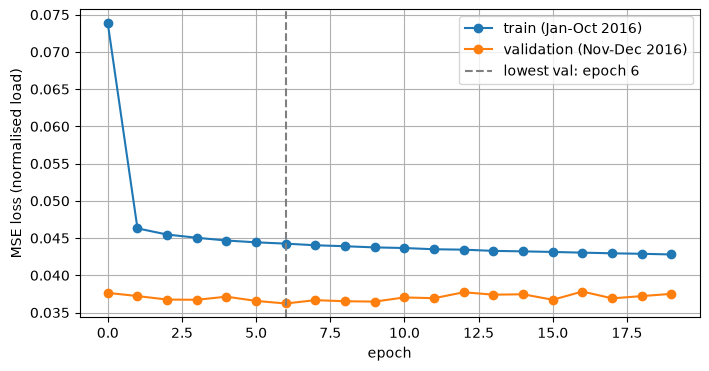

In [31]:
import matplotlib.pyplot as plt

torch.manual_seed(0)
model = nn.Sequential(nn.Linear(7, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses, val_losses = [], []
for epoch in range(20):
    model.train()
    perm = torch.randperm(len(Xf))
    total = 0.0
    for i in range(0, len(Xf), 1024):
        idx = perm[i:i + 1024]
        loss = loss_fn(model(Xf[idx]), yf[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(idx)
    train_losses.append(total / len(Xf))

    model.eval()
    with torch.no_grad():
        val_losses.append(loss_fn(model(Xv), yv).item())
    print("epoch", epoch, "train", round(train_losses[-1], 4), "val", round(val_losses[-1], 4))

best_epoch = int(np.argmin(val_losses))
plt.figure(figsize=(8, 4))
plt.plot(train_losses, marker="o", label="train (Jan-Oct 2016)")
plt.plot(val_losses, marker="o", label="validation (Nov-Dec 2016)")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"lowest val: epoch {best_epoch}")
plt.xlabel("epoch")
plt.ylabel("MSE loss (normalised load)")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
X = nn_inputs(data)
mu, sd = X.loc[is_train, cols].mean(), X.loc[is_train, cols].std()
X[cols] = (X[cols] - mu) / sd

Xtr, ytr, Xte = to_t(is_train), to_t(is_train, "load_n"), to_t(is_test)
test = data[is_test].copy()
by_b = test.groupby("building")

def mae_per_building(pred):
    err = (test["load"] - pred).abs()
    return err.groupby(test["building"]).mean()

best = np.minimum(mae_per_building(test["lag24"]), mae_per_building(test["lag168"]))

def score(pred):
    imp = (best - mae_per_building(pred)) / best
    return (imp > 0).mean(), imp.median()

def train_nn(seed, epochs=7):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(7, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 1024):
            idx = perm[i:i + 1024]
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).squeeze(1).numpy()

rows = []
for seed in range(5):
    pred_nn = train_nn(seed) * test["scale"].to_numpy()
    gbm = HistGradientBoostingRegressor(random_state=seed)
    gbm.fit(data.loc[is_train, feats], data.loc[is_train, "load_n"])
    pred_gbm = gbm.predict(test[feats]) * test["scale"].to_numpy()
    for name, pred in [("nn", pred_nn), ("gbm", pred_gbm)]:
        share, med = score(pred)
        rows.append({"seed": seed, "model": name, "share": share, "median": med})
    print("seed", seed, "done")

res = pd.DataFrame(rows)
print(res.pivot(index="seed", columns="model", values=["share", "median"]).round(3))
print(res.groupby("model")[["share", "median"]].agg(["mean", "std"]).round(3))

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
      share       median       
model   gbm    nn    gbm     nn
seed                           
0      0.79  0.78  0.123  0.088
1      0.79  0.77  0.122  0.092
2      0.79  0.73  0.122  0.080
3      0.79  0.69  0.121  0.077
4      0.79  0.69  0.123  0.066
       share        median       
        mean    std   mean    std
model                            
gbm    0.790  0.000  0.122  0.001
nn     0.732  0.043  0.081  0.010


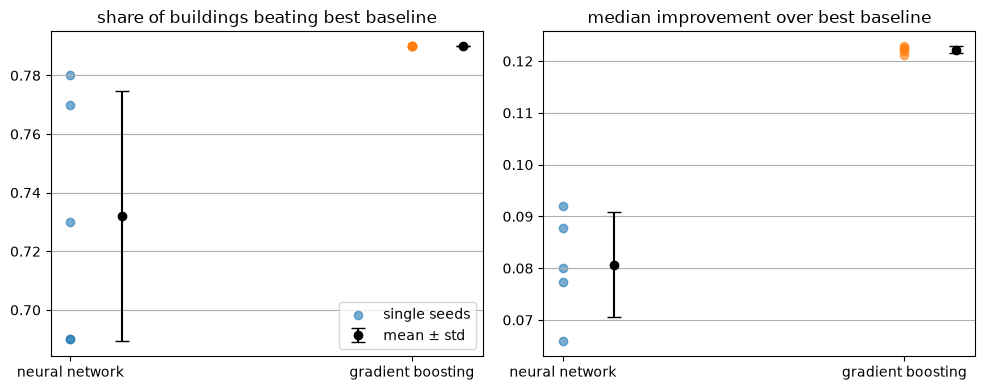

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in [(axes[0], "share", "share of buildings beating best baseline"),
                          (axes[1], "median", "median improvement over best baseline")]:
    for x, name in enumerate(["nn", "gbm"]):
        vals = res.loc[res["model"] == name, metric]
        ax.scatter([x] * len(vals), vals, alpha=0.6, label="single seeds" if x == 0 else None)
        ax.errorbar(x + 0.15, vals.mean(), yerr=vals.std(), fmt="o", color="black",
                    capsize=5, label="mean ± std" if x == 0 else None)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["neural network", "gradient boosting"])
    ax.set_title(title)
    ax.grid(True, axis="y")
axes[0].legend()
plt.tight_layout()
plt.show()